In [7]:
import kagglehub
path = kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset")

Using Colab cache for faster access to the 'default-of-credit-card-clients-dataset' dataset.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Construct the path to the downloaded CSV dataset
csv_path = os.path.join(path, "UCI_Credit_Card.csv")

df = pd.read_csv(csv_path)
df.head()          # first 5 rows
df.shape           # (rows, columns)
df.info()          # column types
df.isnull().sum()  # missing values (should be 0)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          30000 non-null  int64  
 1   LIMIT_BAL                   30000 non-null  float64
 2   SEX                         30000 non-null  int64  
 3   EDUCATION                   30000 non-null  int64  
 4   MARRIAGE                    30000 non-null  int64  
 5   AGE                         30000 non-null  int64  
 6   PAY_0                       30000 non-null  int64  
 7   PAY_2                       30000 non-null  int64  
 8   PAY_3                       30000 non-null  int64  
 9   PAY_4                       30000 non-null  int64  
 10  PAY_5                       30000 non-null  int64  
 11  PAY_6                       30000 non-null  int64  
 12  BILL_AMT1                   30000 non-null  float64
 13  BILL_AMT2                   300

,0
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0


In [14]:
# Step 3: Clean the data
df = df.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"})
df = df.drop(columns=["ID"])
df = df.drop_duplicates()

# Some categories have undocumented values; group them into "other"
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

# Quick confirmation check
print(f"New shape: {df.shape}")
print(df.columns)

KeyError: "['ID'] not found in axis"

0.22125813449023862


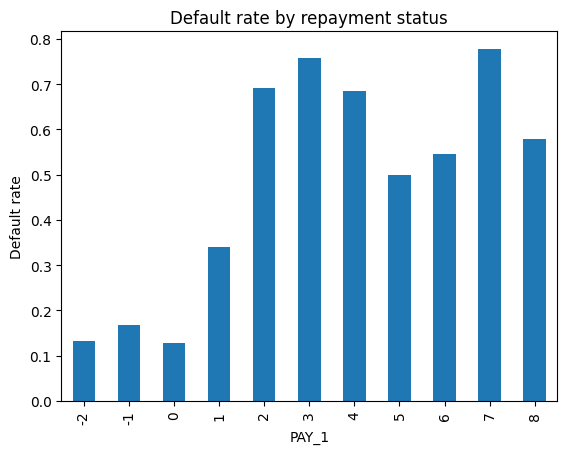

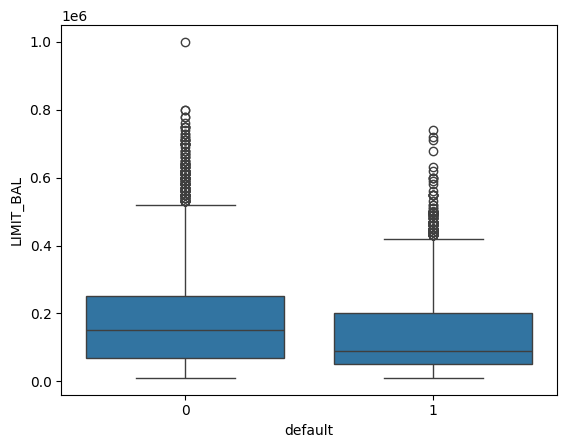

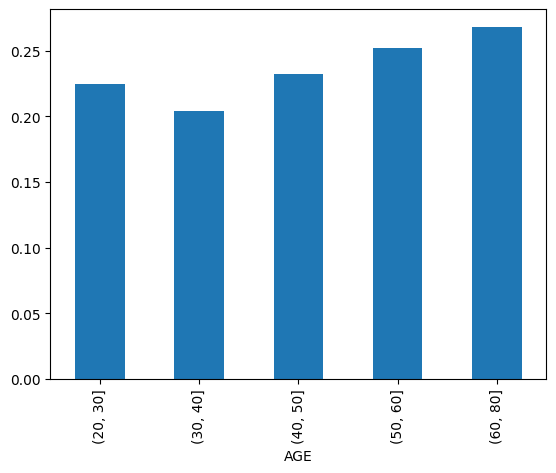

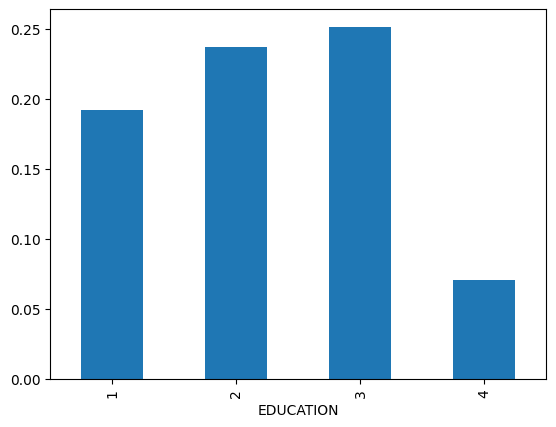

In [10]:
#Step 4 Exploratory data analysis
#what is the mean of default
print(df["default"].mean())   # about 0.22, so ~22% default

# Does payment history matter? (PAY_1 = repayment status last month; higher = more months late)
df.groupby("PAY_1")["default"].mean().plot(kind="bar")
plt.title("Default rate by repayment status")
plt.ylabel("Default rate")
plt.show()

# Does credit limit matter?
sns.boxplot(x="default", y="LIMIT_BAL", data=df)
plt.show()

# Does age matter?
df.groupby(pd.cut(df["AGE"], [20,30,40,50,60,80]), observed=True)["default"].mean().plot(kind="bar")
plt.show()

# Does education matter?
df.groupby("EDUCATION")["default"].mean().plot(kind="bar")
plt.show()


In [12]:
#Step 6, build the models
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X = df.drop(columns=["default"])
y = df["default"]

# 80% to learn from, 20% hidden for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Model 1: Logistic Regression
log_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
log_model.fit(X_train, y_train)

# Model 2: Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

=== Logistic ===
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4667
           1       0.73      0.25      0.37      1326

    accuracy                           0.81      5993
   macro avg       0.77      0.61      0.63      5993
weighted avg       0.80      0.81      0.78      5993

ROC-AUC: 0.7160243240544227


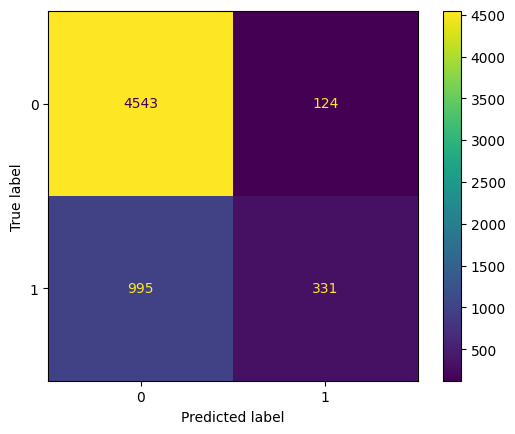



=== Random Forest ===
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4667
           1       0.63      0.36      0.46      1326

    accuracy                           0.81      5993
   macro avg       0.73      0.65      0.67      5993
weighted avg       0.79      0.81      0.79      5993

ROC-AUC: 0.7605034514341413


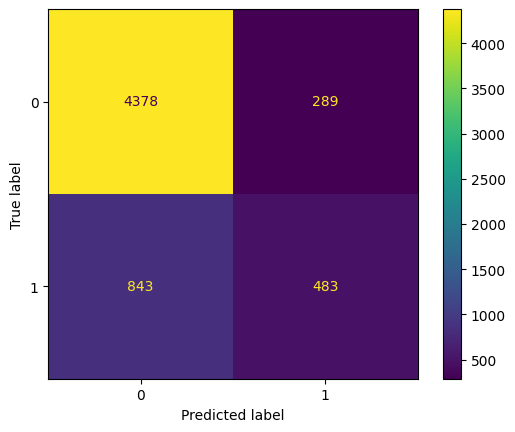



Cross-validation AUC scores for Logistic Regression:
[0.69892212 0.70987585 0.73019469 0.73692983 0.73267334]


In [15]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)

# Calculate probability of default (PD) for both models
log_probs = log_model.predict_proba(X_test)[:, 1]
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# Evaluate and plot the models
for name, model, probs in [("Logistic", log_model, log_probs), ("Random Forest", rf_model, rf_probs)]:
    preds = model.predict(X_test)
    print(f"=== {name} ===")
    print(classification_report(y_test, preds))
    print("ROC-AUC:", roc_auc_score(y_test, probs))
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds)).plot()
    plt.show()
    print("\n")

# Cross-validation: tests the model on 5 different splits
print("Cross-validation AUC scores for Logistic Regression:")
print(cross_val_score(log_model, X, y, cv=5, scoring="roc_auc"))

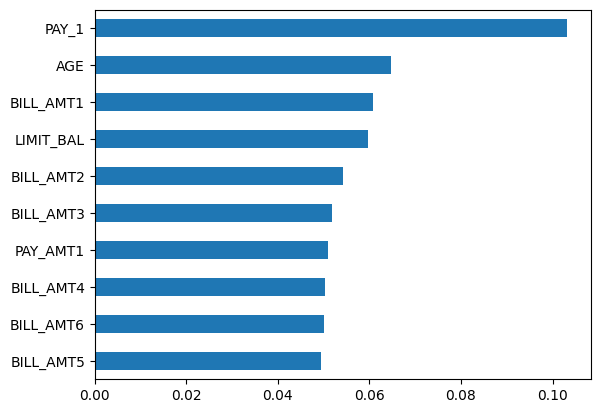

In [16]:
pd.Series(rf_model.feature_importances_, index=X.columns).sort_values().tail(10).plot(kind="barh")
plt.show() #this should compare both the models

In [18]:
#add database using SQLITE
import sqlite3
conn = sqlite3.connect("credit.db")
df.to_sql("loans", conn, if_exists="replace", index=False)

def q(sql):
    return pd.read_sql(sql, conn)

In [19]:
#Write queries
# Default rate by education
q("""
SELECT EDUCATION, COUNT(*) AS borrowers, ROUND(AVG("default"), 3) AS default_rate
FROM loans
GROUP BY EDUCATION
ORDER BY default_rate DESC
""")

# Default rate by credit limit band
q("""
SELECT CASE WHEN LIMIT_BAL < 50000 THEN 'Low'
            WHEN LIMIT_BAL < 150000 THEN 'Medium'
            ELSE 'High' END AS limit_band,
       COUNT(*) AS borrowers,
       ROUND(AVG("default"), 3) AS default_rate,
       ROUND(AVG(BILL_AMT1), 0) AS avg_balance
FROM loans
GROUP BY limit_band
""")

# CTE example: high-risk segments (late payers) vs. the overall rate
q("""
WITH overall AS (SELECT AVG("default") AS overall_rate FROM loans)
SELECT PAY_1, COUNT(*) AS borrowers, ROUND(AVG("default"), 3) AS default_rate,
       ROUND((SELECT overall_rate FROM overall), 3) AS overall_rate
FROM loans
GROUP BY PAY_1
HAVING AVG("default") > (SELECT overall_rate FROM overall)
""")

,PAY_1,borrowers,default_rate,overall_rate
0,1,3667,0.340,0.221
1,2,2666,0.691,0.221
2,3,322,0.758,0.221
3,4,76,0.684,0.221
4,5,26,0.500,0.221
5,6,11,0.545,0.221
6,7,9,0.778,0.221
7,8,19,0.579,0.221


In [20]:
#The basic credit risk formula
out = X_test.copy()
out["actual_default"] = y_test
out["PD"] = rf_probs
out["EAD"] = out["BILL_AMT1"].clip(lower=0)   # assumption: latest bill = amount owed
LGD = 0.45                                     # assumption: 45% loss if default
out["expected_loss"] = out["PD"] * LGD * out["EAD"]
out["risk_band"] = pd.cut(out["PD"], [0, 0.2, 0.5, 1.0], labels=["Low", "Medium", "High"], include_lowest=True)

out.to_csv("credit_risk_scored.csv", index=False)

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
